In [1]:
import pandas as pd
import nltk 
import re
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk import pos_tag
from nltk import RegexpParser
from nltk.tokenize import sent_tokenize 
from nltk import Tree
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from nltk.stem import PorterStemmer
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet as wn
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from transformers import TFBertModel, AutoTokenizer
from transformers import GPT2Tokenizer, GPT2LMHeadModel
from sentence_transformers import SentenceTransformer
from sklearn.cluster import DBSCAN
from scipy.spatial.distance import cosine
from concurrent.futures import ProcessPoolExecutor, as_completed
import warnings
import time
from concurrent.futures import ThreadPoolExecutor
from transformers import logging
from matplotlib.ticker import MaxNLocator
import math
from transformers import pipeline
from functools import partial
from scipy.optimize import curve_fit
import json
import itertools
import networkx as nx
import statsmodels.api as sm

warnings.filterwarnings('ignore')
logging.set_verbosity_error()  # disable warnings from transformer, hugging face package.

In [2]:
## get all the stories.  nine stories in total.
story_all = [] 

data = pd.read_pickle("../boyscout.pkl")
story_all.append(data)
data = pd.read_pickle("../schissel_v1-pool.pkl")
story_all.append(data)
data = pd.read_pickle("../schissel_v2-lake.pkl")
story_all.append(data)
data = pd.read_pickle("../triplett_v1-rookie.pkl")
story_all.append(data)
data = pd.read_pickle("../triplett_v2-catlady.pkl")
story_all.append(data)
data = pd.read_pickle("../panic.pkl")
story_all.append(data)
data = pd.read_pickle("../hester_v1-park.pkl")
story_all.append(data)
data = pd.read_pickle("../hester_v2-church.pkl")
story_all.append(data)
data = pd.read_pickle("../stein.pkl")
story_all.append(data)

In [3]:
## use the clauses in the original dataset.
story_processed_all = [story_all[i]['segmentation'] for i in np.arange(9)]
story_processed_marked = [string.split("\n") for string in story_processed_all]  # split into single clauses.
story_processed_all = [[item[3:] if item[2] == "." 
                        else item[2:] if item[1] == "."
                        else item[4:] for item in story_processed_marked[story]] for story in np.arange(9)]

recall_processed_all = [story_all[i]['recalls segmented'] for i in np.arange(len(story_processed_all))]
recall_processed_marked = [[participant.split("\n") for participant in recall_processed_all[story]]
                        for story in np.arange(9)]
recall_processed_all = [[ [element[3:] if len(element) > 2 and element[2] == "." else
                           element[2:] if len(element) > 2 and element[1] == "." else
                           element[4:] if len(element) > 2 else
                           ""  for element in participant] for participant in recall_processed_marked[story]]
                        for story in np.arange(9)]

score_processed_all = [story_all[i]['recall scores'] for i in np.arange(len(story_processed_all))]
for i in np.arange(len(score_processed_all)):
    recall_score_each = score_processed_all[i].values
    score_processed_all[i] = recall_score_each.tolist()
    # print(score_processed_all[i])

# print(story_processed_all[7])
# print(recall_processed_all[0][0])   # clear clause of each participant.
# print("")
# print("recalled narrative clauses:", score_processed_all)

In [4]:
## three more stories added to the analysis.
story_additional = [] 
recall_additional = []

data = pd.read_csv("../bear-segments.csv", encoding='ISO-8859-1')
story_additional.append(data)
recall = pd.read_csv("../bear-recalls_segmented.csv", encoding='ISO-8859-1')
recall_additional.append(recall)

data = pd.read_csv("../costa-segments.csv", encoding='utf-8')
story_additional.append(data)
recall = pd.read_csv("../costa-recalls_segmented.csv", encoding='utf-8')
recall_additional.append(recall)

data = pd.read_csv("../do-something-segments.csv", encoding='ISO-8859-1')
story_additional.append(data)
recall = pd.read_csv("../dosomething-recalls_segmented.csv", encoding='ISO-8859-1')
recall_additional.append(recall)


In [5]:
additional_story_processed = []
additional_recall_processed = [[] for _ in np.arange(3)]
score_processed_additional = []

for i in np.arange(3):
    # the original story in segment.
    story = story_additional[i]['segment_text']
    story_as_list = story.tolist()
    additional_story_processed.append(story_as_list)

    # get the recall text by each participant.
    recall = recall_additional[i]
    recall_id = recall['recall_id']
    recall_id_set = list(set(recall_id))
    for j in recall_id_set:
        recall_participant = recall[recall['recall_id'] == j]
        recall_content = recall_participant['clause_text']
        recall_as_list = recall_content.tolist()
        additional_recall_processed[i].append(recall_as_list)

    # get the recall score of each narrative clause. - the final score in the csv directly.
    score_processed_additional.append(story_additional[i]['proc'])
    score_processed_add = [series_item.tolist() for series_item in score_processed_additional]
    score_processed = [[float(p.strip('%')) for p in percent_list] 
                                      for percent_list in score_processed_add]

In [6]:
## add the new data to the dataset.
story_processed_all = story_processed_all + additional_story_processed
recall_processed_all = recall_processed_all + additional_recall_processed

clauses = [len(story_processed_all[i]) for i in np.arange(len(story_processed_all))]
print("clauses in each story: ", clauses )

clauses in each story:  [19, 18, 18, 32, 32, 56, 54, 54, 130, 122, 194, 81]


In [7]:
### look at other data in the datasets.
data = pd.read_pickle("../boyscout.pkl")

data.keys()

data['recall scores']  # the recalled clause in the original story for each participant. need to calculate the recall percentage myself to get the score line.


5aa18536dbdb470001ef2cf1            [1, 2, 5, 7, 8, 9, 10, 14, 16, 17, 19]
5f0b196928879b23ce83e097                                    [7, 9, 11, 19]
5d5db7f7ca179000180b17cc         [1, 2, 5, 6, 7, 8, 9, 10, 11, 14, 16, 18]
5ac0eabce1546900019bd744    [2, 4, 5, 6, 7, 9, 10, 11, 12, 15, 16, 17, 19]
60693e637bc58fc13d57b1a7          [6, 7, 8, 9, 10, 14, 15, 16, 17, 18, 19]
                                                 ...                      
5ea806dea2d63e011f551ef6                              [1, 6, 7, 8, 17, 19]
5d95fc8c7f79070017f92e93       [1, 2, 5, 7, 8, 10, 13, 14, 16, 17, 18, 19]
5ceef0cd45c1ec001920d548                                    [2, 5, 14, 19]
63f7792ffa2f18ec31a85d24                            [2, 3, 5, 7, 8, 9, 14]
640226e83e2c4614c50dff0e                           [2, 5, 6, 7, 9, 17, 19]
Length: 100, dtype: object

In [8]:
model = SentenceTransformer('all-MiniLM-L6-v2')

story_emb_all = [model.encode(story) for story in story_processed_all]

recall_emb_all = [[model.encode(participant) for participant in story]
                    for story in recall_processed_all]

## Pairwise cosine distance within recalls and narratives. between recall and narrative.

Story 1: 19 clauses, 171 unique pairs, mean cosine distance = 0.7448
Story 2: 18 clauses, 153 unique pairs, mean cosine distance = 0.7390
Story 3: 18 clauses, 153 unique pairs, mean cosine distance = 0.7636
Story 4: 32 clauses, 496 unique pairs, mean cosine distance = 0.8072
Story 5: 32 clauses, 496 unique pairs, mean cosine distance = 0.7963
Story 6: 56 clauses, 1540 unique pairs, mean cosine distance = 0.7624
Story 7: 54 clauses, 1431 unique pairs, mean cosine distance = 0.7959
Story 8: 54 clauses, 1431 unique pairs, mean cosine distance = 0.7781
Story 9: 130 clauses, 8385 unique pairs, mean cosine distance = 0.7997
Story 10: 122 clauses, 7381 unique pairs, mean cosine distance = 0.7864
Story 11: 194 clauses, 18721 unique pairs, mean cosine distance = 0.7662
Story 12: 81 clauses, 3240 unique pairs, mean cosine distance = 0.8035


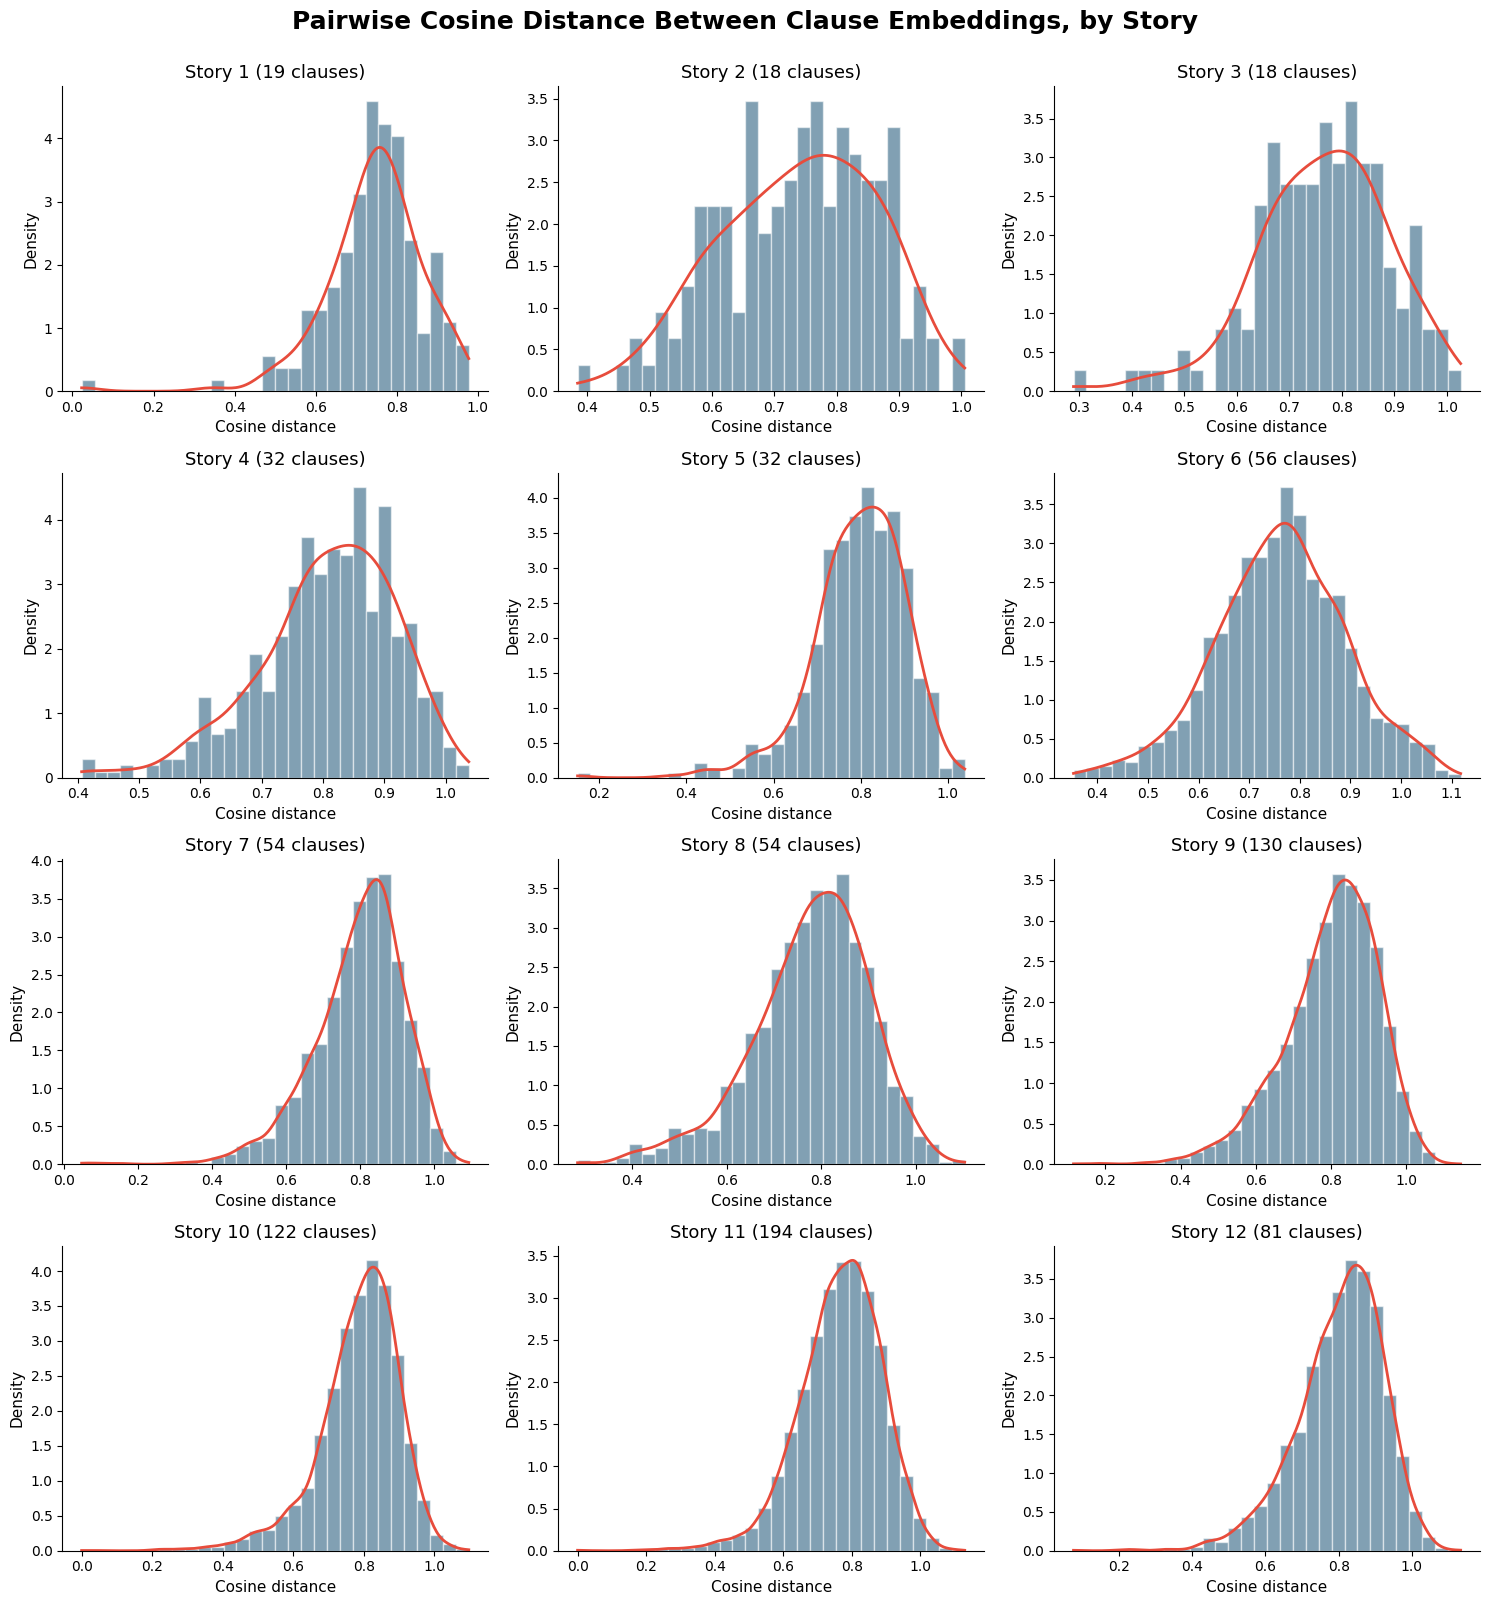

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist
from scipy.stats import gaussian_kde

# ── pairwise cosine distances between unique clause-embedding pairs, per story ──
pairwise_cosine_distances = [
    pdist(story_emb_all[i], metric='cosine')   # condensed form: every unique pair, no diagonal
    for i in range(len(story_emb_all))
]

for i, dists in enumerate(pairwise_cosine_distances):
    n_clauses = len(story_emb_all[i])
    print(f"Story {i+1}: {n_clauses} clauses, {len(dists)} unique pairs, "
          f"mean cosine distance = {dists.mean():.4f}")

# ── histogram (density) + KDE curve, one panel per story ───────────────────
fig, axes = plt.subplots(4, 3, figsize=(15, 16))
axes = axes.flatten()

for i, dists in enumerate(pairwise_cosine_distances):
    ax = axes[i]
    ax.hist(dists, bins=30, density=True, color='#1a5276', alpha=0.55, edgecolor='white')

    kde = gaussian_kde(dists)
    x_grid = np.linspace(dists.min(), dists.max(), 300)
    ax.plot(x_grid, kde(x_grid), color='#e74c3c', linewidth=2)

    ax.set_title(f"Story {i+1} ({len(story_emb_all[i])} clauses)", fontsize=13)
    ax.set_xlabel("Cosine distance", fontsize=11)
    ax.set_ylabel("Density", fontsize=11)
    ax.spines[['top', 'right']].set_visible(False)

for ax in axes[len(pairwise_cosine_distances):]:
    ax.set_visible(False)

fig.suptitle("Pairwise Cosine Distance Between Clause Embeddings, by Story",
             fontsize=18, fontweight='bold', y=1.0)
plt.tight_layout()
plt.show()


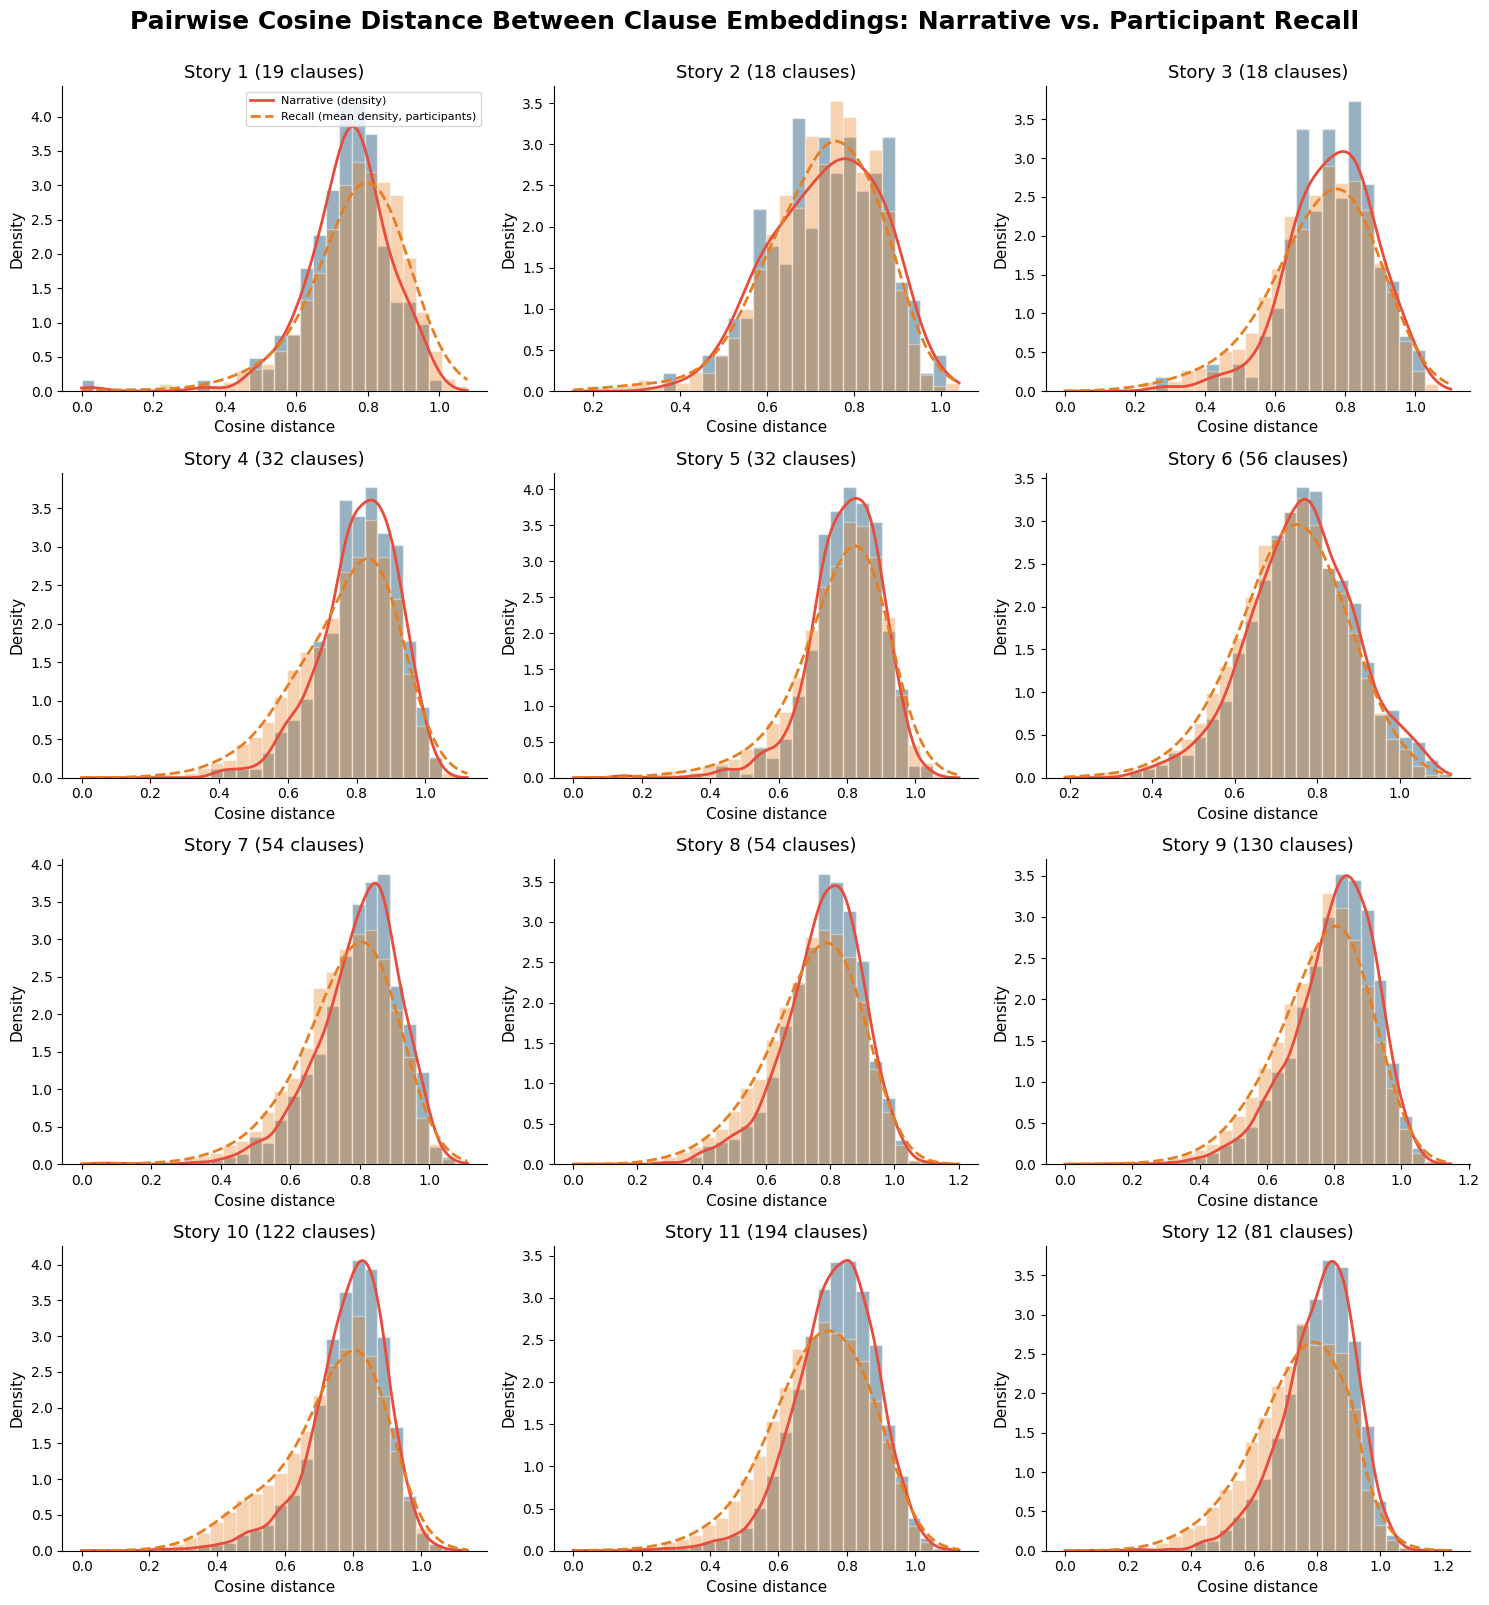

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist
from scipy.stats import gaussian_kde

n_bins = 30
n_stories = len(story_emb_all)

fig, axes = plt.subplots(4, 3, figsize=(15, 16))
axes = axes.flatten()

for i in range(n_stories):
    ax = axes[i]

    # ── narrative: pairwise cosine distances between unique clause pairs ────
    story_dists = pdist(story_emb_all[i], metric='cosine')

    # ── participant recalls: pairwise distances within each participant's own
    #    recalled clauses, then averaged (histogram + KDE) across participants ──
    recall_dists_per_participant = [
        pdist(participant_embs, metric='cosine')
        for participant_embs in recall_emb_all[i]
        if len(participant_embs) >= 2
    ]

    # shared bin edges / x-grid across both distributions, for a fair overlay
    all_vals = np.concatenate([story_dists] + recall_dists_per_participant) \
        if recall_dists_per_participant else story_dists
    x_min, x_max = all_vals.min(), all_vals.max()
    bin_edges    = np.linspace(x_min, x_max, n_bins + 1)
    bin_centers  = (bin_edges[:-1] + bin_edges[1:]) / 2
    bin_width    = bin_edges[1] - bin_edges[0]
    x_grid       = np.linspace(x_min, x_max, 300)

    # narrative histogram + KDE
    ax.hist(story_dists, bins=bin_edges, density=True,
            color='#1a5276', alpha=0.45, edgecolor='white')
    story_kde = gaussian_kde(story_dists)
    ax.plot(x_grid, story_kde(x_grid), color='#e74c3c', linewidth=2, label='Narrative (density)')

    # participant recall: mean histogram + mean KDE across participants
    if recall_dists_per_participant:
        participant_hists = np.array([
            np.histogram(d, bins=bin_edges, density=True)[0]
            for d in recall_dists_per_participant
        ])
        mean_hist_recall = participant_hists.mean(axis=0)
        ax.bar(bin_centers, mean_hist_recall, width=bin_width,
               color='#e67e22', alpha=0.35, edgecolor='white')

        participant_kdes = []
        for d in recall_dists_per_participant:
            if len(np.unique(d)) < 2:
                continue
            try:
                kde = gaussian_kde(d)
                participant_kdes.append(kde(x_grid))
            except Exception:
                continue
        if participant_kdes:
            mean_kde_recall = np.mean(participant_kdes, axis=0)
            ax.plot(x_grid, mean_kde_recall, color='#e67e22', linewidth=2,
                    linestyle='--', label='Recall (mean density, participants)')

    ax.set_title(f"Story {i+1} ({len(story_emb_all[i])} clauses)", fontsize=13)
    ax.set_xlabel("Cosine distance", fontsize=11)
    ax.set_ylabel("Density", fontsize=11)
    ax.spines[['top', 'right']].set_visible(False)

axes[0].legend(fontsize=8, loc='upper right')

for ax in axes[n_stories:]:
    ax.set_visible(False)

fig.suptitle("Pairwise Cosine Distance Between Clause Embeddings: Narrative vs. Participant Recall",
             fontsize=18, fontweight='bold', y=1.0)
plt.tight_layout()
plt.show()


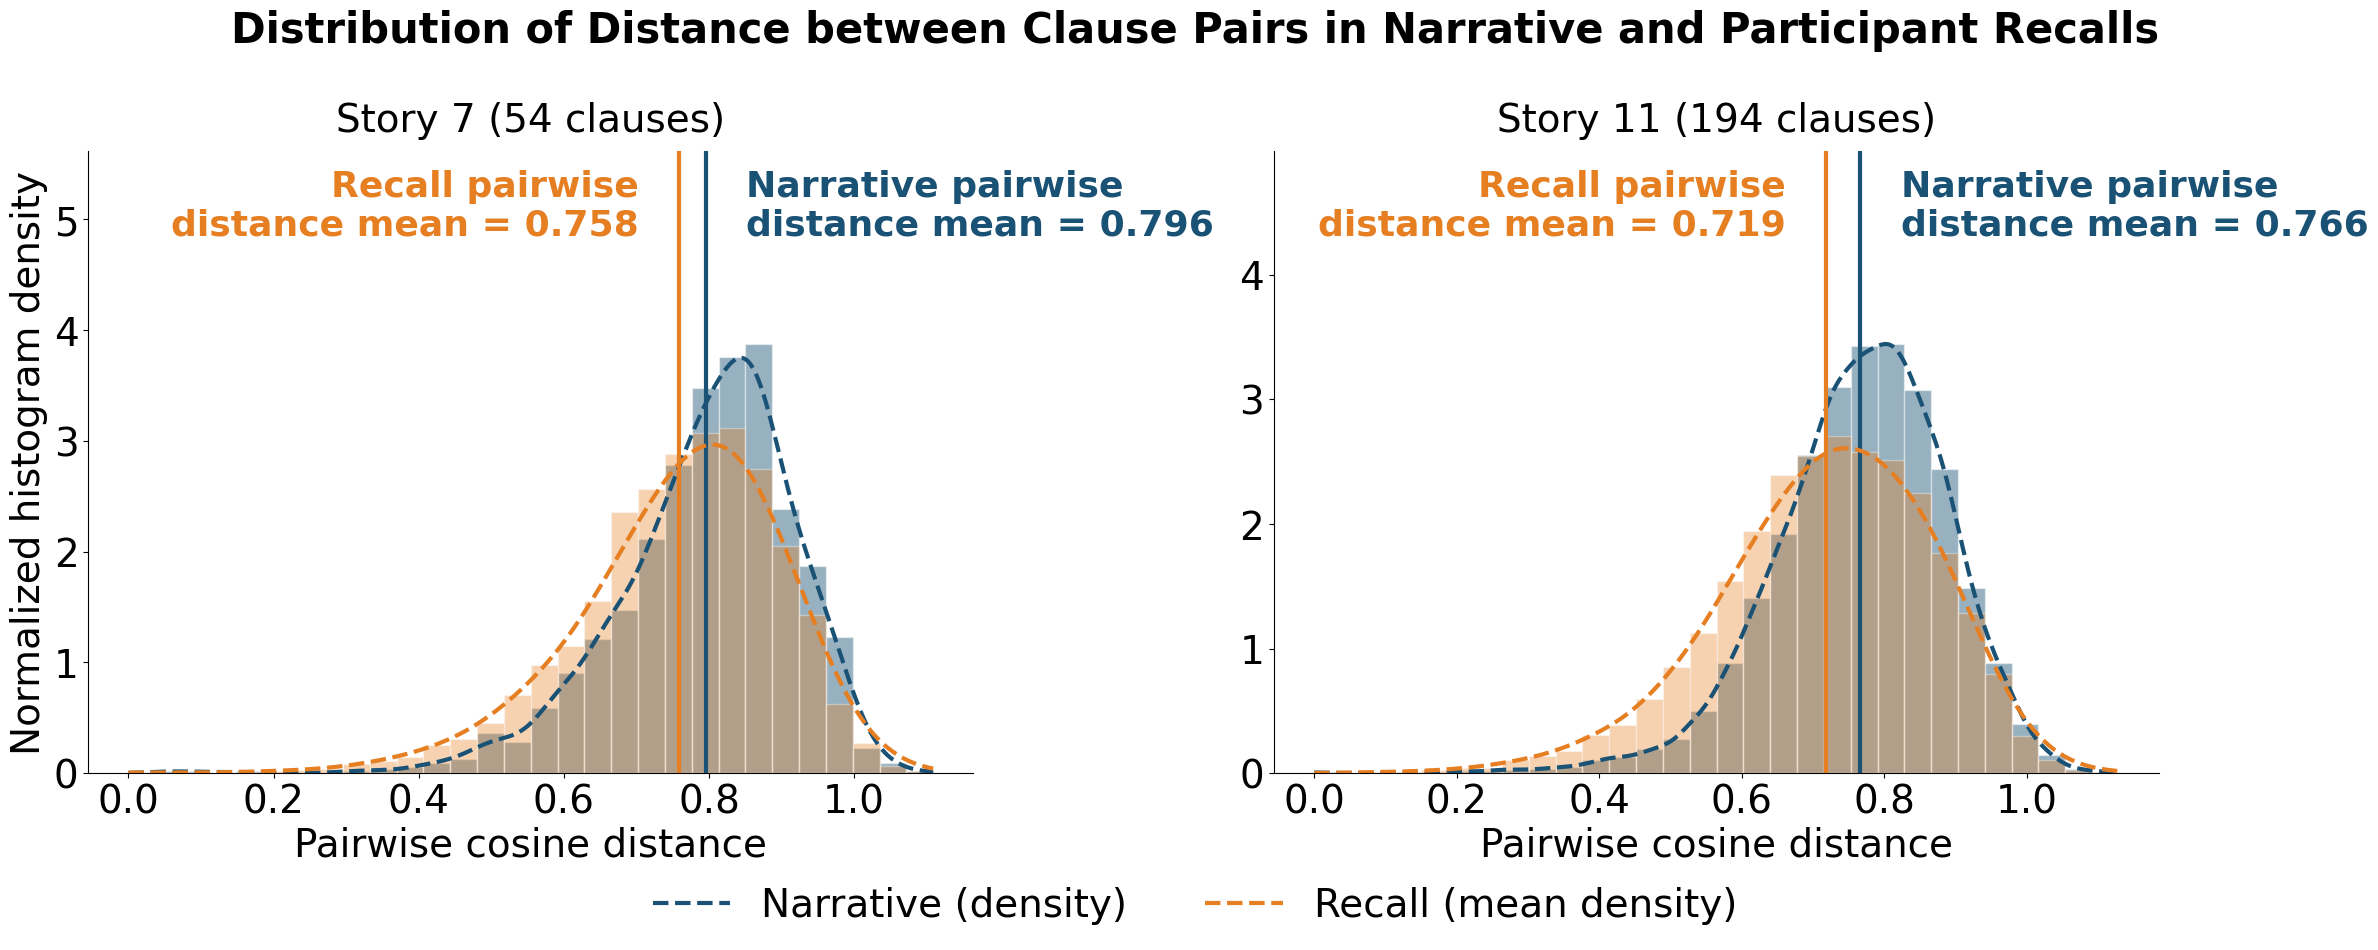

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.transforms import blended_transform_factory
from scipy.spatial.distance import pdist
from scipy.stats import gaussian_kde

n_bins = 30
selected_stories = [6, 10]   # 0-indexed

# ── font sizes (all >= 25) ────────────────────────────────────────────────────
fs_suptitle, fs_title, fs_label, fs_tick, fs_legend, fs_mean = 30, 28, 28, 28, 28, 26

narr_color, recall_color = '#1a5276', '#e67e22'

fig, axes = plt.subplots(1, 2, figsize=(24, 10))
legend_handles = []

for panel, (ax, i) in enumerate(zip(axes, selected_stories)):

    # ── narrative: pairwise cosine distances between unique clause pairs ────
    story_dists = pdist(story_emb_all[i], metric='cosine')

    # ── participant recalls: pairwise distances within each participant's own
    #    recalled clauses, then averaged (histogram + KDE) across participants ──
    recall_dists_per_participant = [
        pdist(participant_embs, metric='cosine')
        for participant_embs in recall_emb_all[i]
        if len(participant_embs) >= 2
    ]

    # shared bin edges / x-grid across both distributions, for a fair overlay
    all_vals = np.concatenate([story_dists] + recall_dists_per_participant) \
        if recall_dists_per_participant else story_dists
    x_min, x_max = all_vals.min(), all_vals.max()
    bin_edges    = np.linspace(x_min, x_max, n_bins + 1)
    bin_centers  = (bin_edges[:-1] + bin_edges[1:]) / 2
    bin_width    = bin_edges[1] - bin_edges[0]
    x_grid       = np.linspace(x_min, x_max, 300)

    y_peak = 0.0

    # narrative histogram + KDE (blue)
    counts, _, _ = ax.hist(story_dists, bins=bin_edges, density=True,
                           color=narr_color, alpha=0.45, edgecolor='white')
    story_kde_vals = gaussian_kde(story_dists)(x_grid)
    story_kde_line, = ax.plot(x_grid, story_kde_vals, color=narr_color, linewidth=3, linestyle='--', label='Narrative (density)')

    y_peak = max(y_peak, counts.max(), story_kde_vals.max())

    story_mean = story_dists.mean()
    ax.axvline(story_mean, color=narr_color, linewidth=3, linestyle='-')
    means = [(story_mean, narr_color, "Narrative pairwise\ndistance mean")]

    recall_kde_line = None

    # participant recall: mean histogram + mean KDE across participants
    if recall_dists_per_participant:
        participant_hists = np.array([
            np.histogram(d, bins=bin_edges, density=True)[0]
            for d in recall_dists_per_participant
        ])
        mean_hist_recall = participant_hists.mean(axis=0)
        ax.bar(bin_centers, mean_hist_recall, width=bin_width,
               color=recall_color, alpha=0.35, edgecolor='white')
        y_peak = max(y_peak, mean_hist_recall.max())

        participant_kdes = []
        for d in recall_dists_per_participant:
            if len(np.unique(d)) < 2:
                continue
            try:
                participant_kdes.append(gaussian_kde(d)(x_grid))
            except Exception:
                continue
        if participant_kdes:
            mean_kde_recall = np.mean(participant_kdes, axis=0)
            recall_kde_line, = ax.plot(x_grid, mean_kde_recall, color=recall_color, linewidth=3,
                                       linestyle='--', label='Recall (mean density)')
            y_peak = max(y_peak, mean_kde_recall.max())

        # recall mean distance: mean of each participant's mean, then across participants
        recall_mean = np.mean([d.mean() for d in recall_dists_per_participant])
        ax.axvline(recall_mean, color=recall_color, linewidth=3, linestyle='-')
        means.append((recall_mean, recall_color, "Recall pairwise\ndistance mean"))

    # headroom above the curves for the mean labels
    ax.set_ylim(0, y_peak * 1.45)

    # mean labels above their lines: smaller mean labelled to the left, larger to the right
    trans = blended_transform_factory(ax.transData, ax.transAxes)
    order = sorted(range(len(means)), key=lambda k: means[k][0])
    for rank, k in enumerate(order):
        value, color, text = means[k]
        ha = 'right' if (rank == 0 and len(means) > 1) else 'left'
        pad = -0.005 if ha == 'right' else 0.005
        ax.text(value + pad * (x_max - x_min) * 10, 0.97, f"{text} = {value:.3f}",
                transform=trans, ha=ha, va='top', fontsize=fs_mean,
                fontweight='bold', color=color, linespacing=1.15)

    ax.set_title(f"Story {i+1} ({len(story_emb_all[i])} clauses)", fontsize=fs_title, pad=14)
    ax.set_xlabel("Pairwise cosine distance", fontsize=fs_label)
    if panel == 0:
        ax.set_ylabel("Normalized histogram density", fontsize=fs_label)
    ax.tick_params(axis='both', labelsize=fs_tick)
    ax.spines[['top', 'right']].set_visible(False)

    if panel == 0:
        legend_handles = [h for h in (story_kde_line, recall_kde_line) if h is not None]

# one legend for both panels, below the plots
fig.legend(handles=legend_handles, fontsize=fs_legend, loc='lower center',
           ncol=len(legend_handles), frameon=False, bbox_to_anchor=(0.5, 0.0))

fig.suptitle("Distribution of Distance between Clause Pairs in Narrative and Participant Recalls",
             fontsize=fs_suptitle, fontweight='bold', y=0.95)
plt.tight_layout(rect=[0, 0.08, 1, 0.93])     # normal gap between the title and the panels

plt.savefig("pairwise_distance_narrative_vs_recall.png", dpi=150, bbox_inches='tight')
plt.show()



Story 1: clauses=  19 | narrative mean=0.7448 | recall mean=0.7675
Story 2: clauses=  18 | narrative mean=0.7390 | recall mean=0.7302
Story 3: clauses=  18 | narrative mean=0.7636 | recall mean=0.7305
Story 4: clauses=  32 | narrative mean=0.8072 | recall mean=0.7668
Story 5: clauses=  32 | narrative mean=0.7963 | recall mean=0.7790
Story 6: clauses=  56 | narrative mean=0.7624 | recall mean=0.7372
Story 7: clauses=  54 | narrative mean=0.7959 | recall mean=0.7582
Story 8: clauses=  54 | narrative mean=0.7781 | recall mean=0.7429
Story 9: clauses= 130 | narrative mean=0.7997 | recall mean=0.7615
Story 10: clauses= 122 | narrative mean=0.7864 | recall mean=0.7356
Story 11: clauses= 194 | narrative mean=0.7662 | recall mean=0.7187
Story 12: clauses=  81 | narrative mean=0.8035 | recall mean=0.7391
  Paired t-test: narrative vs. recall mean cosine distance
  n pairs (stories)     = 12
  mean narrative        = 0.7786
  mean recall           = 0.7473
  mean difference       = 0.0313  (narr

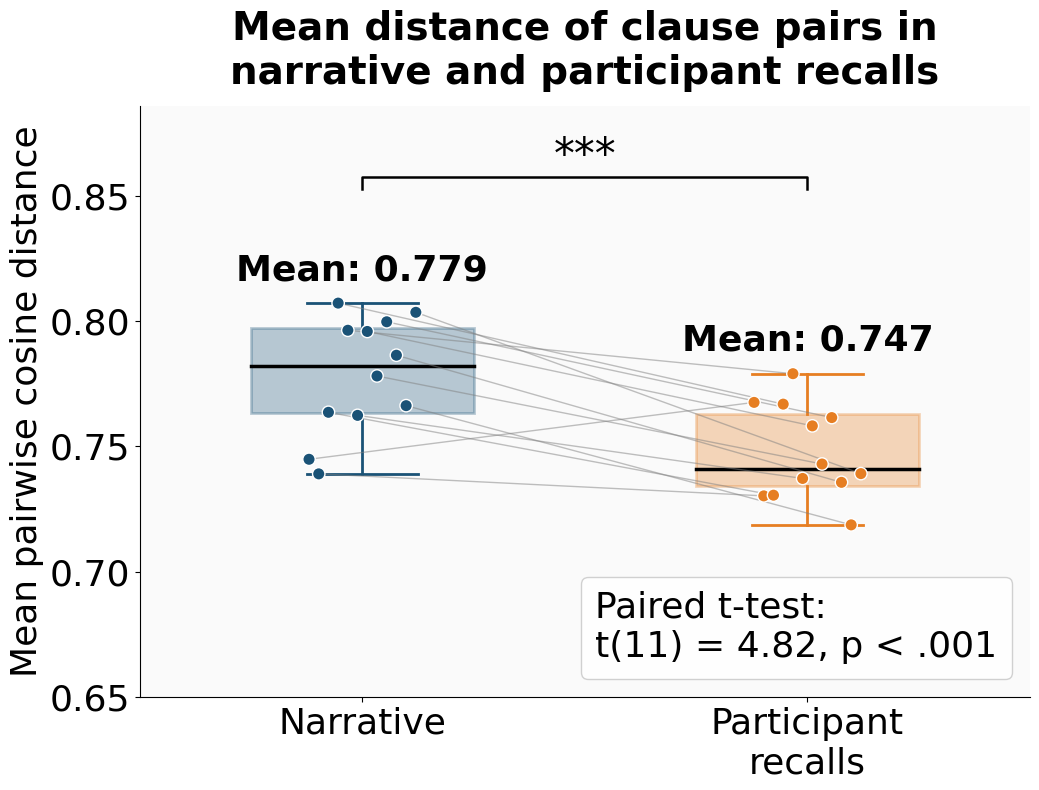

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist
from scipy.stats import ttest_rel, t as sp_t
from matplotlib.lines import Line2D
import pingouin as pg

n_stories    = len(story_emb_all)
clause_story = [len(story) for story in story_processed_all]

# ── narrative: mean pairwise cosine distance per story ───────────────────────
mean_story_distance = np.array([pdist(story_emb_all[i], metric='cosine').mean()
                                for i in range(n_stories)], dtype=float)

# ── recall: mean over participants of each participant's mean pairwise distance ─
mean_recall_distance = []
for i in range(n_stories):
    participant_means = [
        pdist(participant_embs, metric='cosine').mean()
        for participant_embs in recall_emb_all[i]
        if len(participant_embs) >= 2
    ]
    mean_recall_distance.append(np.mean(participant_means) if participant_means else np.nan)
mean_recall_distance = np.array(mean_recall_distance, dtype=float)

for i in range(n_stories):
    print(f"Story {i+1}: clauses={clause_story[i]:>4d} | "
          f"narrative mean={mean_story_distance[i]:.4f} | recall mean={mean_recall_distance[i]:.4f}")

# ── paired t-test + full stats report ───────────────────────────────────────
valid = ~(np.isnan(mean_story_distance) | np.isnan(mean_recall_distance))
x, y  = mean_story_distance[valid], mean_recall_distance[valid]
n, dof = len(x), len(x) - 1

t_stat, p_value = ttest_rel(x, y)
diffs     = x - y
mean_diff = diffs.mean()
sd_diff   = diffs.std(ddof=1)
cohens_dz = mean_diff / sd_diff
se_diff   = sd_diff / np.sqrt(n)
t_crit    = sp_t.ppf(0.975, df=dof)
ci_lower, ci_upper = mean_diff - t_crit * se_diff, mean_diff + t_crit * se_diff

print("=" * 60)
print("  Paired t-test: narrative vs. recall mean cosine distance")
print("=" * 60)
print(f"  n pairs (stories)     = {n}")
print(f"  mean narrative        = {x.mean():.4f}")
print(f"  mean recall           = {y.mean():.4f}")
print(f"  mean difference       = {mean_diff:.4f}  (narrative − recall)")
print(f"  SD of differences     = {sd_diff:.4f}")
print(f"  95% CI of difference  = [{ci_lower:.4f}, {ci_upper:.4f}]")
print(f"  t({dof})               = {t_stat:.4f}")
print(f"  p-value               = {p_value:.4g}")
print(f"  Cohen's d_z           = {cohens_dz:.4f}")
print("=" * 60)
print("\nPingouin full report:")
print(pg.ttest(x, y, paired=True).to_string(index=False))

def add_stars(p):
    if p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return 'ns'

p_text   = "p < .001" if p_value < 0.001 else f"p = {p_value:.3f}"
tt_label = f"Paired t-test:\nt({dof}) = {t_stat:.2f}, {p_text}"

# ── boxplot ───────────────────────────────────────────────────────────────────
fs_title, fs_label, fs_tick, fs_mean, fs_legend, fs_star = 28, 26, 26, 26, 26, 30

names     = ["Narrative", "Participant\nrecalls"]
data      = [mean_story_distance, mean_recall_distance]
colors    = ['#1a5276', '#e67e22']
positions = np.arange(2)

y_bottom  = 0.65
y_min_dat = min(np.nanmin(d) for d in data)
y_max_all = max(np.nanmax(d) for d in data)
if y_min_dat < y_bottom:
    print(f"Warning: lowest value {y_min_dat:.3f} is below the axis bottom {y_bottom}; "
          f"some points will be cut off.")
span = y_max_all - y_bottom                          # visible data range, used for spacing

fig, ax = plt.subplots(figsize=(10.5, 8))
fig.patch.set_facecolor('white')
ax.set_facecolor('#fafafa')

bp = ax.boxplot([d[~np.isnan(d)] for d in data], positions=positions, widths=0.5,
                patch_artist=True, showfliers=False,
                medianprops=dict(color='black', lw=2.5), zorder=2)
for i, color in enumerate(colors):
    bp['boxes'][i].set(facecolor=color, alpha=0.3, edgecolor=color, lw=2)
    for part in ('whiskers', 'caps'):
        for line in bp[part][2 * i: 2 * i + 2]:
            line.set(color=color, lw=2)

# mean value of each box
for i, d in enumerate(data):
    v = d[~np.isnan(d)]
    ax.text(positions[i], v.max() + 0.04 * span, f"Mean: {v.mean():.3f}",
            ha='center', va='bottom', fontsize=fs_mean, fontweight='bold',
            color='black', zorder=6)

# dots per story, connected between the two boxes
offsets = np.linspace(-0.12, 0.12, n_stories)
for s in range(n_stories):
    xs = positions + offsets[s]
    ys = np.array([d[s] for d in data])
    if not np.isnan(ys).any():
        ax.plot(xs, ys, color='grey', lw=1, alpha=0.5, zorder=3)
    ok = ~np.isnan(ys)
    ax.scatter(xs[ok], ys[ok], c=[colors[i] for i in np.where(ok)[0]], s=80,
               edgecolors='white', linewidths=1, zorder=5)

# significance bracket (paired t-test)
yb, tick = y_max_all + 0.32 * span, 0.03 * span
ax.plot([0, 0, 1, 1], [yb - tick, yb, yb, yb - tick], color='black', lw=1.8, zorder=6)
ax.text(0.5, yb, add_stars(p_value), ha='center', va='bottom', fontsize=fs_star, zorder=6)

# axes & labels
ax.set_xticks(positions)
ax.set_xticklabels(names, fontsize=fs_label)
ax.tick_params(axis='y', labelsize=fs_tick)
ax.set_ylabel("Mean pairwise cosine distance", fontsize=fs_label)
ax.set_title("Mean distance of clause pairs in\nnarrative and participant recalls",
             fontsize=fs_title, fontweight='bold', pad=16)
ax.set_ylim(y_bottom, y_max_all + 0.5 * span)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(handles=[Line2D([], [], linestyle='none')], labels=[tt_label],
          loc='lower right', fontsize=fs_legend, handlelength=0, handletextpad=0,
          frameon=True, framealpha=0.9)

plt.tight_layout()
plt.savefig("pairwise_distance_narrative_vs_recall_boxplot.png", dpi=150,
            bbox_inches='tight', facecolor='white')
plt.show()


In [27]:
from scipy.stats import ttest_rel, t as sp_t
import numpy as np
import pingouin as pg

mean_story_arr  = np.array(mean_story_distance, dtype=float)
mean_recall_arr = np.array(mean_recall_distance, dtype=float)
valid = ~np.isnan(mean_recall_arr)

x = mean_story_arr[valid]
y = mean_recall_arr[valid]
n = len(x)
dof = n - 1

# ── paired t-test ────────────────────────────────────────────────────────
t_stat, p_value = ttest_rel(x, y)

# ── effect size: Cohen's d_z for paired samples ─────────────────────────
diffs      = x - y
mean_diff  = np.mean(diffs)
sd_diff    = np.std(diffs, ddof=1)
cohens_dz  = mean_diff / sd_diff

# ── 95% CI of the mean difference ───────────────────────────────────────
se_diff    = sd_diff / np.sqrt(n)
t_crit     = sp_t.ppf(0.975, df=dof)
ci_lower   = mean_diff - t_crit * se_diff
ci_upper   = mean_diff + t_crit * se_diff

print("=" * 60)
print("  Paired t-test: narrative vs. recall mean cosine distance")
print("=" * 60)
print(f"  n pairs (stories)     = {n}")
print(f"  mean narrative        = {np.mean(x):.4f}")
print(f"  mean recall           = {np.mean(y):.4f}")
print(f"  mean difference       = {mean_diff:.4f}  (narrative − recall)")
print(f"  SD of differences     = {sd_diff:.4f}")
print(f"  95% CI of difference  = [{ci_lower:.4f}, {ci_upper:.4f}]")
print(f"  t({dof})               = {t_stat:.4f}")
print(f"  p-value               = {p_value:.4g}")
print(f"  Cohen's d_z           = {cohens_dz:.4f}")
print("=" * 60)

# ── cross-check + power via pingouin ────────────────────────────────────
report = pg.ttest(x, y, paired=True)
print("\nPingouin full report:")
print(report.to_string(index=False))


  Paired t-test: narrative vs. recall mean cosine distance
  n pairs (stories)     = 12
  mean narrative        = 0.7786
  mean recall           = 0.7473
  mean difference       = 0.0313  (narrative − recall)
  SD of differences     = 0.0225
  95% CI of difference  = [0.0170, 0.0456]
  t(11)               = 4.8151
  p-value               = 0.0005401
  Cohen's d_z           = 1.3900

Pingouin full report:
       T  dof alternative   p-val        CI95%  cohen-d   BF10    power
4.815094   11   two-sided 0.00054 [0.02, 0.05] 1.488366 67.609 0.996615


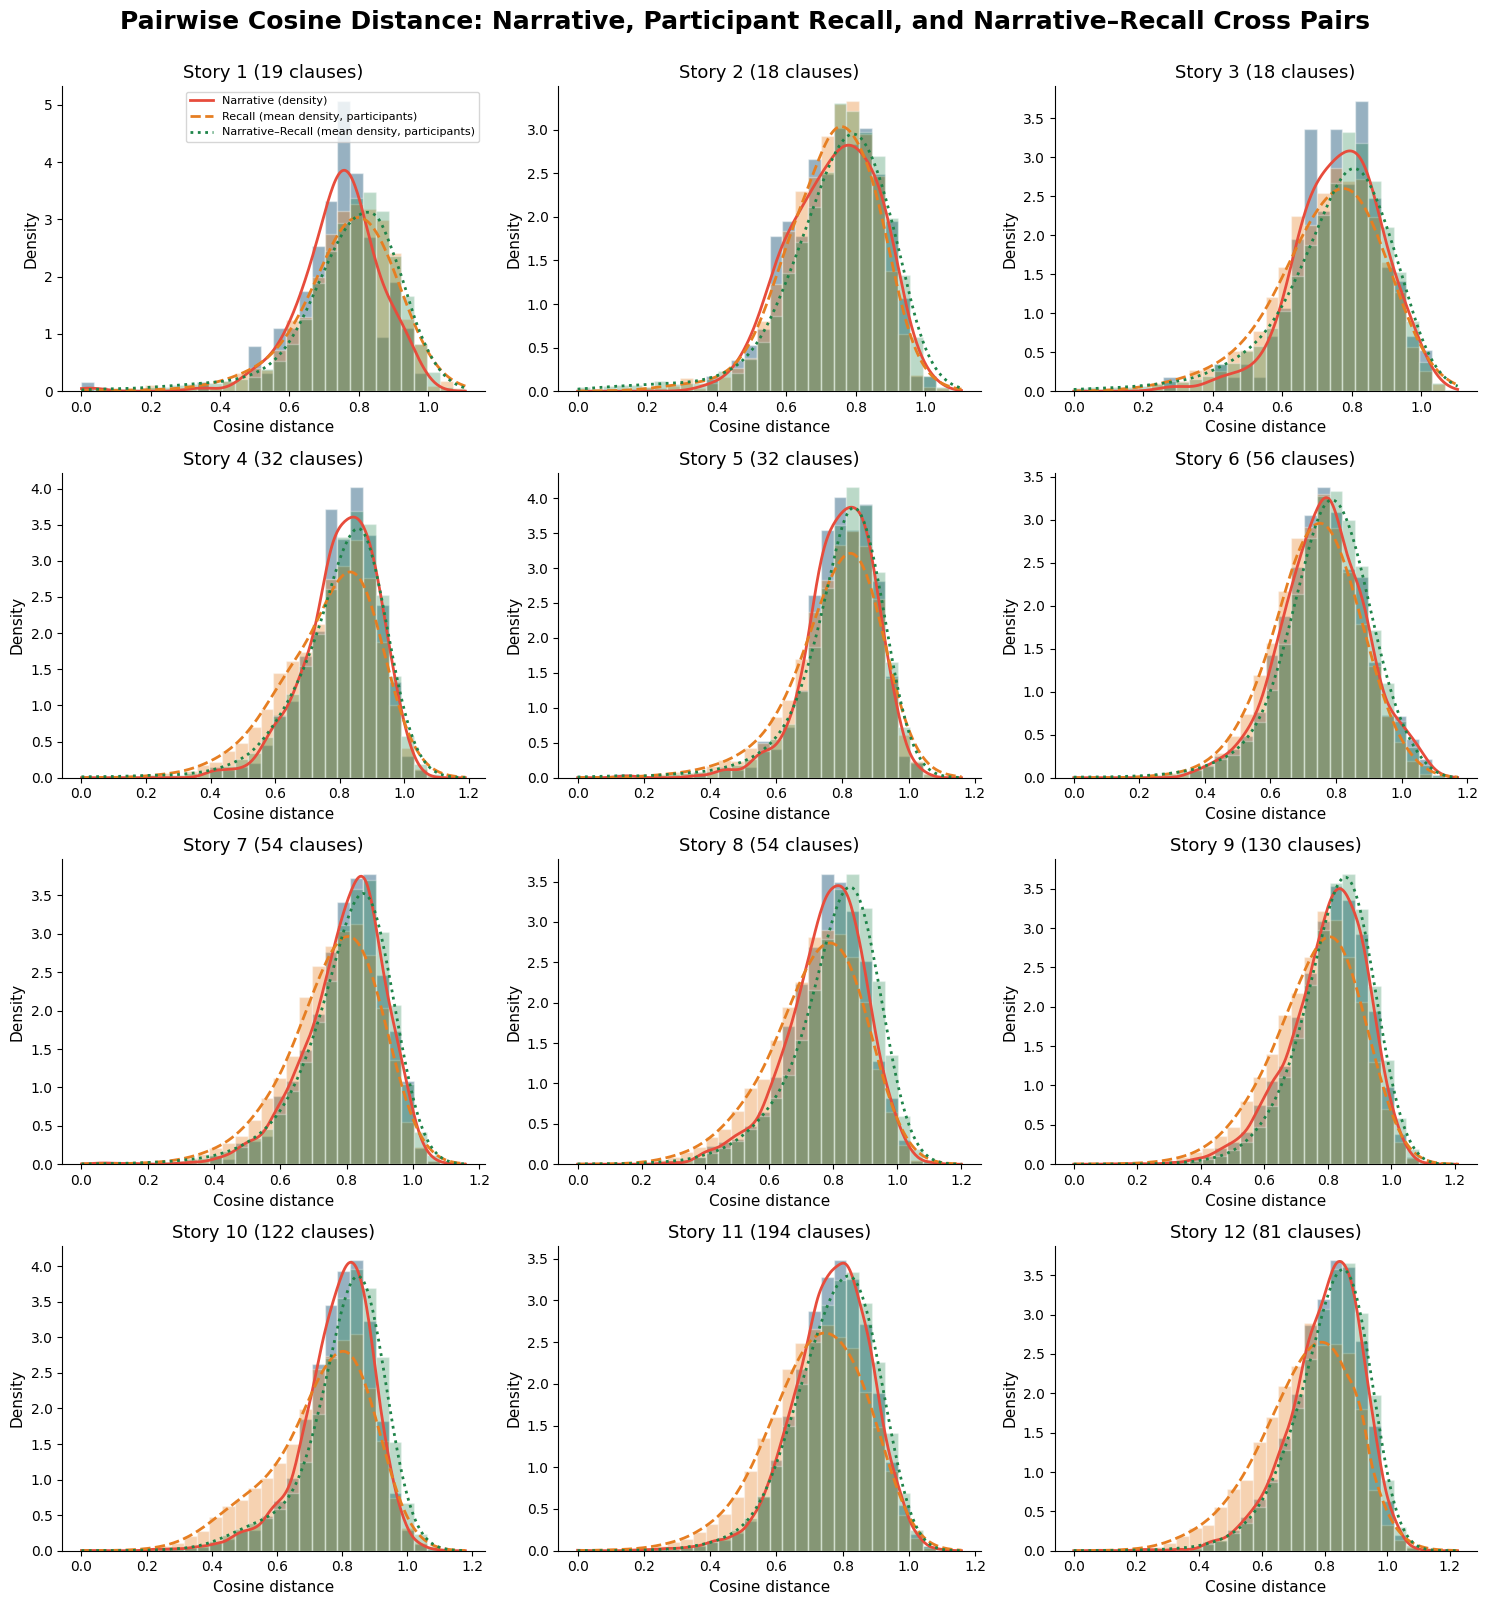

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, cdist
from scipy.stats import gaussian_kde

n_bins = 30
n_stories = len(story_emb_all)

fig, axes = plt.subplots(4, 3, figsize=(15, 16))
axes = axes.flatten()

for i in range(n_stories):
    ax = axes[i]

    # ── narrative: pairwise cosine distances between unique clause pairs ────
    story_dists = pdist(story_emb_all[i], metric='cosine')

    # ── participant recalls: pairwise distances within each participant's own
    #    recalled clauses, then averaged (histogram + KDE) across participants ──
    recall_dists_per_participant = [
        pdist(participant_embs, metric='cosine')
        for participant_embs in recall_emb_all[i]
        if len(participant_embs) >= 2
    ]

    # ── narrative-recall cross pairs: every narrative clause vs. every one of a
    #    participant's recalled clauses, then averaged (histogram + KDE) across participants ──
    cross_dists_per_participant = [
        cdist(story_emb_all[i], participant_embs, metric='cosine').flatten()
        for participant_embs in recall_emb_all[i]
        if len(participant_embs) >= 1
    ]

    # shared bin edges / x-grid across all three distributions, for a fair overlay
    all_vals_parts = [story_dists]
    if recall_dists_per_participant:
        all_vals_parts += recall_dists_per_participant
    if cross_dists_per_participant:
        all_vals_parts += cross_dists_per_participant
    all_vals = np.concatenate(all_vals_parts)
    x_min, x_max = all_vals.min(), all_vals.max()
    bin_edges    = np.linspace(x_min, x_max, n_bins + 1)
    bin_centers  = (bin_edges[:-1] + bin_edges[1:]) / 2
    bin_width    = bin_edges[1] - bin_edges[0]
    x_grid       = np.linspace(x_min, x_max, 300)

    # narrative histogram + KDE
    ax.hist(story_dists, bins=bin_edges, density=True,
            color='#1a5276', alpha=0.45, edgecolor='white')
    story_kde = gaussian_kde(story_dists)
    ax.plot(x_grid, story_kde(x_grid), color='#e74c3c', linewidth=2, label='Narrative (density)')

    # participant recall: mean histogram + mean KDE across participants
    if recall_dists_per_participant:
        participant_hists = np.array([
            np.histogram(d, bins=bin_edges, density=True)[0]
            for d in recall_dists_per_participant
        ])
        mean_hist_recall = participant_hists.mean(axis=0)
        ax.bar(bin_centers, mean_hist_recall, width=bin_width,
               color='#e67e22', alpha=0.35, edgecolor='white')

        participant_kdes = []
        for d in recall_dists_per_participant:
            if len(np.unique(d)) < 2:
                continue
            try:
                kde = gaussian_kde(d)
                participant_kdes.append(kde(x_grid))
            except Exception:
                continue
        if participant_kdes:
            mean_kde_recall = np.mean(participant_kdes, axis=0)
            ax.plot(x_grid, mean_kde_recall, color='#e67e22', linewidth=2,
                    linestyle='--', label='Recall (mean density, participants)')

    # narrative-recall cross pairs: mean histogram + mean KDE across participants
    if cross_dists_per_participant:
        cross_hists = np.array([
            np.histogram(d, bins=bin_edges, density=True)[0]
            for d in cross_dists_per_participant
        ])
        mean_hist_cross = cross_hists.mean(axis=0)
        ax.bar(bin_centers, mean_hist_cross, width=bin_width,
               color='#1e8449', alpha=0.30, edgecolor='white')

        cross_kdes = []
        for d in cross_dists_per_participant:
            if len(np.unique(d)) < 2:
                continue
            try:
                kde = gaussian_kde(d)
                cross_kdes.append(kde(x_grid))
            except Exception:
                continue
        if cross_kdes:
            mean_kde_cross = np.mean(cross_kdes, axis=0)
            ax.plot(x_grid, mean_kde_cross, color='#1e8449', linewidth=2,
                    linestyle=':', label='Narrative–Recall (mean density, participants)')

    ax.set_title(f"Story {i+1} ({len(story_emb_all[i])} clauses)", fontsize=13)
    ax.set_xlabel("Cosine distance", fontsize=11)
    ax.set_ylabel("Density", fontsize=11)
    ax.spines[['top', 'right']].set_visible(False)

axes[0].legend(fontsize=8, loc='upper right')

for ax in axes[n_stories:]:
    ax.set_visible(False)

fig.suptitle("Pairwise Cosine Distance: Narrative, Participant Recall, and Narrative–Recall Cross Pairs",
             fontsize=18, fontweight='bold', y=1.0)
plt.tight_layout()
plt.show()


Story 1: clauses=  19 | narrative mean=0.7448 ± 0.0278 | recall mean=0.7675 ± 0.0053 | cross mean=0.7709 ± 0.0037
Story 2: clauses=  18 | narrative mean=0.7390 ± 0.0292 | recall mean=0.7302 ± 0.0073 | cross mean=0.7461 ± 0.0051
Story 3: clauses=  18 | narrative mean=0.7636 ± 0.0293 | recall mean=0.7305 ± 0.0050 | cross mean=0.7526 ± 0.0034
Story 4: clauses=  32 | narrative mean=0.8072 ± 0.0197 | recall mean=0.7668 ± 0.0042 | cross mean=0.8016 ± 0.0020
Story 5: clauses=  32 | narrative mean=0.7963 ± 0.0187 | recall mean=0.7790 ± 0.0033 | cross mean=0.7977 ± 0.0018
Story 6: clauses=  56 | narrative mean=0.7624 ± 0.0172 | recall mean=0.7372 ± 0.0038 | cross mean=0.7708 ± 0.0030
Story 7: clauses=  54 | narrative mean=0.7959 ± 0.0165 | recall mean=0.7582 ± 0.0040 | cross mean=0.8013 ± 0.0020
Story 8: clauses=  54 | narrative mean=0.7781 ± 0.0167 | recall mean=0.7429 ± 0.0042 | cross mean=0.8060 ± 0.0026
Story 9: clauses= 130 | narrative mean=0.7997 ± 0.0110 | recall mean=0.7615 ± 0.0037 | c

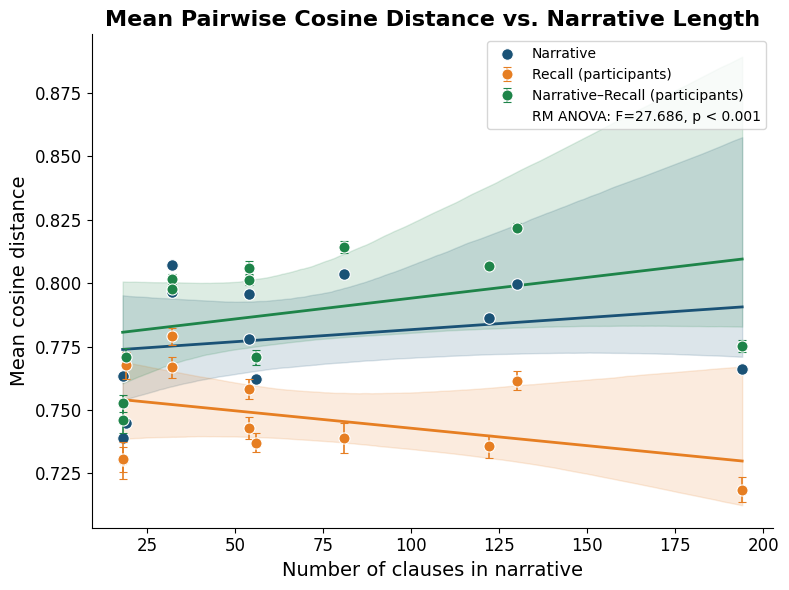

In [33]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import pandas as pd
import pingouin as pg
from scipy.spatial.distance import pdist, cdist
from matplotlib.lines import Line2D

n_stories = len(story_emb_all)
clause_story = [len(story) for story in story_processed_all]

# ── narrative: mean pairwise cosine distance + SE (from # of clauses) ──────
mean_story_distance = []
se_story_distance = []
for i in range(n_stories):
    dists = pdist(story_emb_all[i], metric='cosine')
    n_clauses_i = clause_story[i]
    mean_story_distance.append(dists.mean())
    se_story_distance.append(
        dists.std(ddof=1) / np.sqrt(n_clauses_i) if n_clauses_i > 1 else np.nan
    )

# ── recall: mean pairwise cosine distance + SE (from # of participants) ────
mean_recall_distance = []
se_recall_distance = []
for i in range(n_stories):
    participant_means = [
        pdist(participant_embs, metric='cosine').mean()
        for participant_embs in recall_emb_all[i]
        if len(participant_embs) >= 2
    ]
    if participant_means:
        n_p = len(participant_means)
        mean_recall_distance.append(np.mean(participant_means))
        se_recall_distance.append(
            np.std(participant_means, ddof=1) / np.sqrt(n_p) if n_p > 1 else np.nan
        )
    else:
        mean_recall_distance.append(np.nan)
        se_recall_distance.append(np.nan)

# ── narrative-recall cross pairs: mean distance + SE (from # of participants) ──
mean_cross_distance = []
se_cross_distance = []
for i in range(n_stories):
    participant_cross_means = [
        cdist(story_emb_all[i], participant_embs, metric='cosine').mean()
        for participant_embs in recall_emb_all[i]
        if len(participant_embs) >= 1
    ]
    if participant_cross_means:
        n_p = len(participant_cross_means)
        mean_cross_distance.append(np.mean(participant_cross_means))
        se_cross_distance.append(
            np.std(participant_cross_means, ddof=1) / np.sqrt(n_p) if n_p > 1 else np.nan
        )
    else:
        mean_cross_distance.append(np.nan)
        se_cross_distance.append(np.nan)

for i in range(n_stories):
    print(f"Story {i+1}: clauses={clause_story[i]:>4d} | "
          f"narrative mean={mean_story_distance[i]:.4f} ± {se_story_distance[i]:.4f} | "
          f"recall mean={mean_recall_distance[i]:.4f} ± {se_recall_distance[i]:.4f} | "
          f"cross mean={mean_cross_distance[i]:.4f} ± {se_cross_distance[i]:.4f}")

# ── repeated-measures ANOVA: narrative vs. recall vs. narrative-recall cross ──
mean_story_arr  = np.array(mean_story_distance, dtype=float)
mean_recall_arr = np.array(mean_recall_distance, dtype=float)
mean_cross_arr  = np.array(mean_cross_distance, dtype=float)
valid = ~np.isnan(mean_recall_arr) & ~np.isnan(mean_cross_arr)

story_ids = np.arange(n_stories)[valid]
n_valid = valid.sum()

df_long = pd.DataFrame({
    'story':     np.tile(story_ids, 3),
    'condition': ['Narrative'] * n_valid + ['Recall'] * n_valid + ['Cross'] * n_valid,
    'distance':  np.concatenate([mean_story_arr[valid], mean_recall_arr[valid], mean_cross_arr[valid]])
})

rm = pg.rm_anova(data=df_long, dv='distance', within='condition', subject='story', detailed=True)
print("=" * 60)
print("  Repeated Measures ANOVA: mean cosine distance by condition")
print("=" * 60)
print(rm[['Source', 'F', 'p-unc', 'ng2', 'eps']].to_string(index=False))
print("=" * 60)

f_stat  = rm.loc[rm['Source'] == 'condition', 'F'].values[0]
p_anova = rm.loc[rm['Source'] == 'condition', 'p-unc'].values[0]
p_anova_str = f"p = {p_anova:.4f}" if p_anova >= 0.001 else "p < 0.001"

# ── post-hoc paired t-tests with FDR ─────────────────────────────────────────
posthoc = pg.pairwise_tests(data=df_long, dv='distance', within='condition',
                             subject='story', padjust='fdr_bh')
print("\nPost-hoc (FDR corrected):")
print(posthoc[['A', 'B', 'T', 'dof', 'p-unc', 'p-corr']].to_string(index=False))

# ── linear fit + bootstrap CI (case resampling of the story-level points) ──
def fit_and_bootstrap_ci(x_data, y_data, label, n_boot=10000, seed=42):
    x_arr = np.array(x_data, dtype=float)
    y_arr = np.array(y_data, dtype=float)
    mask = ~np.isnan(y_arr)
    x_arr, y_arr = x_arr[mask], y_arr[mask]
    n_pts = len(x_arr)

    X = sm.add_constant(x_arr)
    model = sm.OLS(y_arr, X).fit()
    intercept, slope = model.params
    p_val = model.pvalues[1]

    x_fit = np.linspace(x_arr.min(), x_arr.max(), 200)
    y_fit = intercept + slope * x_fit

    rng = np.random.default_rng(seed)
    boot_fits, boot_slopes = [], []

    for _ in range(n_boot):
        idx = rng.integers(0, n_pts, size=n_pts)
        x_sample, y_sample = x_arr[idx], y_arr[idx]
        if np.std(x_sample) == 0:
            continue
        X_sample = sm.add_constant(x_sample)
        boot_model = sm.OLS(y_sample, X_sample).fit()
        b_intercept, b_slope = boot_model.params
        boot_fits.append(b_intercept + b_slope * x_fit)
        boot_slopes.append(b_slope)

    boot_fits   = np.array(boot_fits)
    boot_slopes = np.array(boot_slopes)

    ci_lo = np.percentile(boot_fits, 2.5, axis=0)
    ci_hi = np.percentile(boot_fits, 97.5, axis=0)
    slope_ci_lo, slope_ci_hi = np.percentile(boot_slopes, [2.5, 97.5])

    print(f"{label}: slope = {slope:.5f}, bootstrap 95% CI = [{slope_ci_lo:.5f}, {slope_ci_hi:.5f}], "
          f"p (parametric) = {p_val:.4f}")

    return x_fit, y_fit, ci_lo, ci_hi, slope, slope_ci_lo, slope_ci_hi

x_fit_narr, y_fit_narr, band_lo_narr, band_hi_narr, slope_narr, ci_lo_narr, ci_hi_narr = fit_and_bootstrap_ci(
    clause_story, mean_story_distance, "Narrative"
)
x_fit_recall, y_fit_recall, band_lo_recall, band_hi_recall, slope_recall, ci_lo_recall, ci_hi_recall = fit_and_bootstrap_ci(
    clause_story, mean_recall_distance, "Recall"
)
x_fit_cross, y_fit_cross, band_lo_cross, band_hi_cross, slope_cross, ci_lo_cross, ci_hi_cross = fit_and_bootstrap_ci(
    clause_story, mean_cross_distance, "Narrative-Recall"
)

# ── plot ─────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(clause_story, mean_story_distance,
           color='#1a5276', s=70, edgecolors='white', linewidths=0.8,
           zorder=3, label='Narrative')
ax.plot(x_fit_narr, y_fit_narr, '-', color='#1a5276', linewidth=2)
ax.fill_between(x_fit_narr, band_lo_narr, band_hi_narr, color='#1a5276', alpha=0.15)

ax.errorbar(clause_story, mean_recall_distance, yerr=se_recall_distance,
            fmt='o', color='#e67e22', ecolor='#e67e22', elinewidth=1.2,
            capsize=3, markersize=8, markeredgecolor='white', markeredgewidth=0.8,
            zorder=3, label='Recall (participants)')
ax.plot(x_fit_recall, y_fit_recall, '-', color='#e67e22', linewidth=2)
ax.fill_between(x_fit_recall, band_lo_recall, band_hi_recall, color='#e67e22', alpha=0.15)

ax.errorbar(clause_story, mean_cross_distance, yerr=se_cross_distance,
            fmt='o', color='#1e8449', ecolor='#1e8449', elinewidth=1.2,
            capsize=3, markersize=8, markeredgecolor='white', markeredgewidth=0.8,
            zorder=3, label='Narrative–Recall (participants)')
ax.plot(x_fit_cross, y_fit_cross, '-', color='#1e8449', linewidth=2)
ax.fill_between(x_fit_cross, band_lo_cross, band_hi_cross, color='#1e8449', alpha=0.15)

ax.set_xlabel("Number of clauses in narrative", fontsize=14)
ax.set_ylabel("Mean cosine distance", fontsize=14)
ax.set_title("Mean Pairwise Cosine Distance vs. Narrative Length", fontsize=16, fontweight='bold')
ax.tick_params(labelsize=12)
ax.spines[['top', 'right']].set_visible(False)

handles, labels = ax.get_legend_handles_labels()
handles.append(Line2D([0], [0], color='none',
                       label=f"RM ANOVA: F={f_stat:.3f}, {p_anova_str}"))
ax.legend(handles=handles, fontsize=10)

plt.tight_layout()
plt.show()
